# Sweep monitor: `mday-1_sweep-feature-history_goss-5-fold-cv`

Run the cell below once; it refreshes until the sweep ends. Top: every finished (setting, window), per window. Bottom: the curves of the one in progress.

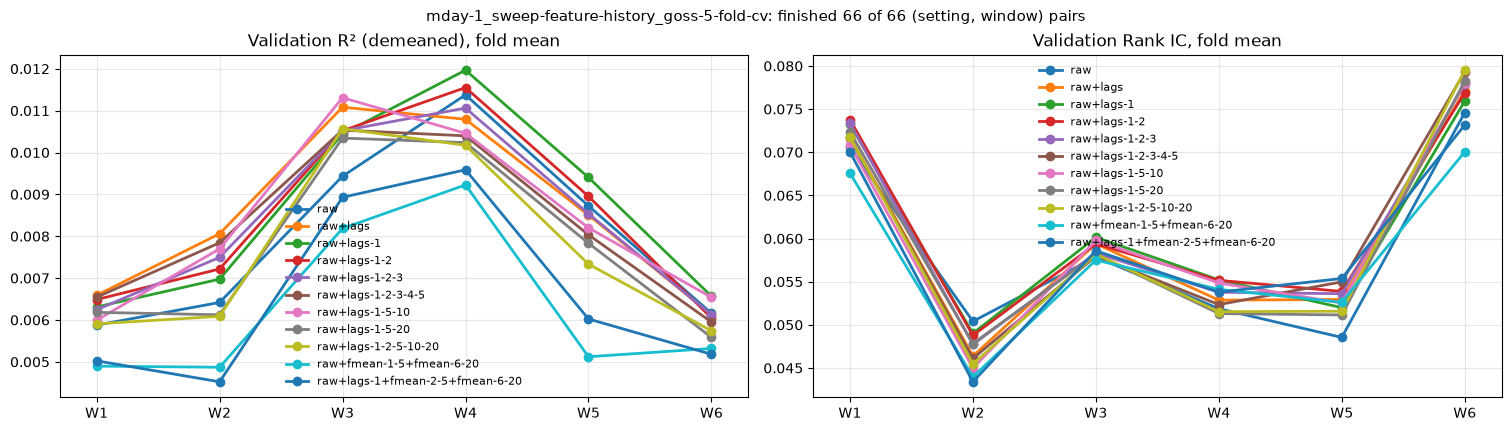

shape: (6, 12)
┌────────┬──────────┬──────────┬────────────┬───┬────────────┬────────────┬────────────┬───────────┐
│ window ┆ raw      ┆ raw+lags ┆ raw+lags-1 ┆ … ┆ raw+lags-1 ┆ raw+lags-1 ┆ raw+fmean- ┆ raw+lags- │
│ ---    ┆ ---      ┆ ---      ┆ ---        ┆   ┆ -5-20      ┆ -2-5-10-20 ┆ 1-5+fmean- ┆ 1+fmean-2 │
│ i64    ┆ f64      ┆ f64      ┆ f64        ┆   ┆ ---        ┆ ---        ┆ 6-20       ┆ -5+fmean- │
│        ┆          ┆          ┆            ┆   ┆ f64        ┆ f64        ┆ ---        ┆ 6-2…      │
│        ┆          ┆          ┆            ┆   ┆            ┆            ┆ f64        ┆ ---       │
│        ┆          ┆          ┆            ┆   ┆            ┆            ┆            ┆ f64       │
╞════════╪══════════╪══════════╪════════════╪═══╪════════════╪════════════╪════════════╪═══════════╡
│ 1      ┆ 0.005876 ┆ 0.006589 ┆ 0.00631    ┆ … ┆ 0.006182   ┆ 0.005907   ┆ 0.004898   ┆ 0.005024  │
│ 2      ┆ 0.006419 ┆ 0.008059 ┆ 0.006975   ┆ … ┆ 0.006124   ┆ 0.006087   ┆ 

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from IPython.display import clear_output

SWEEP_DIR = Path("/workspaces/TimeSeries48/pre-runs/mday-1_sweep-feature-history_goss-5-fold-cv")
CONFIGS = ["raw", "raw+lags", "raw+lags-1", "raw+lags-1-2", "raw+lags-1-2-3", "raw+lags-1-2-3-4-5", "raw+lags-1-5-10", "raw+lags-1-5-20", "raw+lags-1-2-5-10-20", "raw+fmean-1-5+fmean-6-20", "raw+lags-1+fmean-2-5+fmean-6-20"]        # Sweep settings in GRID order (colours C0, C1, ...).
N_WINDOWS = 6
SWEEP_PID = 1339920          # Process ID of the sweep.
REFRESH_SECONDS = 3
FOLD_COLORS = ["C3", "C4", "C9", "C6", "C8", "C5", "C7"]
_r2_cache: dict = {}


def read_json(path: Path) -> dict | None:
    try:
        return json.loads(path.read_text())
    except (OSError, json.JSONDecodeError):
        return None


def demeaned_r2(path: Path) -> float:
    """Fold-mean R² of the per-day demeaned out-of-fold predictions (cached)."""
    key = (path, path.stat().st_mtime)
    if key not in _r2_cache:
        df = pl.read_parquet(path).with_columns(
            pl.col("Prediction") - pl.col("Prediction").mean().over("Date"))
        r2 = [1 - ((f["label"] - f["Prediction"]) ** 2).mean()
              / f["label"].var(ddof=0) for f in df.partition_by("fold")]
        _r2_cache[key] = sum(r2) / len(r2)
    return _r2_cache[key]


def scan() -> tuple[list[dict], tuple | None]:
    """Finished (config, window) results, and the newest unfinished curves file."""
    done, running = [], None
    tags = sorted({f.stem.removeprefix("curves_") for c in CONFIGS
                   for f in (SWEEP_DIR / c / "curves").glob("curves_*.json")})
    for c in CONFIGS:
        for f in (SWEEP_DIR / c / "curves").glob("curves_*.json"):
            d = read_json(f)
            if d is None:
                continue
            tag = f.stem.removeprefix("curves_")
            val = SWEEP_DIR / c / "validation" / f"validation_{tag}.parquet"
            best = d["best_iteration"]
            if best is not None and val.exists():
                done.append({
                    "config": c, "window": tags.index(tag) + 1, "trees": best,
                    "val R² (demeaned)": demeaned_r2(val),
                    "val Rank IC": d["curves"]["val"]["rank_ic"][best - 1],
                })
            elif running is None or f.stat().st_mtime > running[3]:
                running = (c, tags.index(tag) + 1, d, f.stat().st_mtime)
    return done, running


def draw_summary(done: list[dict]) -> plt.Figure:
    """Per window: demeaned validation R² and Rank IC of every finished setting."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
    table = pl.DataFrame(done) if done else None
    for k, c in enumerate(CONFIGS):
        rows = table.filter(pl.col("config") == c).sort("window") if done else None
        if rows is None or rows.is_empty():
            continue
        metrics = ["val R² (demeaned)", "val Rank IC"]
        for ax, metric in zip(axes, metrics, strict=True):
            ax.plot(rows["window"], rows[metric], "o-", c=f"C{k}", lw=2, ms=6,
                    label=c)
    for ax, title in zip(axes, ["Validation R² (demeaned), fold mean",
                                "Validation Rank IC, fold mean"], strict=True):
        ax.set_title(title)
        ticks = range(1, N_WINDOWS + 1)
        ax.set_xticks(ticks, [f"W{w}" for w in ticks])
        ax.set_xlim(0.7, N_WINDOWS + 0.3)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, frameon=False)
    fig.suptitle(f"{SWEEP_DIR.name}: finished {len(done)} of "
                 f"{len(CONFIGS) * N_WINDOWS} (setting, window) pairs", fontsize=11)
    return fig


def draw_running(config: str, window: int, d: dict) -> plt.Figure:
    """The (setting, window) in progress: fold-mean and per-fold curves."""
    c, folds = d["curves"], d.get("folds", {})
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), layout="constrained")
    axes[0].plot(c["train"]["r2"], c="C0", label="train (fold mean)")
    axes[0].plot(c["val"]["r2"], c="C1", label="val (fold mean)")
    axes[0].set_title("R²")
    for k, v in enumerate(folds.get("val_r2", [])):
        axes[1].plot(v, c=FOLD_COLORS[k % 7], lw=1.2, label=f"fold {k + 1}")
    axes[1].plot(c["val"]["r2"], c="black", lw=2, label="mean")
    axes[1].set_title("Validation R² per fold")
    for k, v in enumerate(folds.get("val_rank_ic", [])):
        axes[2].plot(v, c=FOLD_COLORS[k % 7], lw=1.2)
    axes[2].plot(c["val"]["rank_ic"], c="black", lw=2, label="mean")
    axes[2].set_title("Validation Rank IC per fold")
    for ax in axes:
        ax.set_xlabel("iteration")
        ax.ticklabel_format(axis="y", useOffset=False)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, frameon=False)
    fig.suptitle(f"Running: {config}, W{window}, {len(c['val']['r2'])} iterations",
                 fontsize=11)
    return fig


# Refresh until the sweep process exits; then save the summary plot and stop.
# Interrupt the cell to stop watching; the sweep is unaffected.
while True:
    alive = Path(f"/proc/{SWEEP_PID}").exists()
    done, running = scan()
    clear_output(wait=True)
    fig = draw_summary(done)
    if not alive:
        (SWEEP_DIR / "plots").mkdir(exist_ok=True)
        fig.savefig(SWEEP_DIR / "plots" / "sweep_summary.png", dpi=120)
    plt.show()
    plt.close(fig)
    if done:
        print(pl.DataFrame(done).pivot(on="config", index="window",
                                       values="val R² (demeaned)").sort("window"))
    if running is not None and alive:
        fig = draw_running(*running[:3])
        plt.show()
        plt.close(fig)
    stamp = time.strftime("%H:%M:%S")
    if not alive:
        print(f"{stamp}: the sweep has exited. Final summary saved to plots/.")
        break
    print(f"{stamp}: sweep running (PID {SWEEP_PID})...")
    time.sleep(REFRESH_SECONDS)
